# FarmTech Solutions — O despertar da Rede Neural
**FIAP | Fase 6 | Grupo 57 (solo)**  
**Viktor Ribeiro dos Santos Cunha | RM570917 | 13/10/2026**

## Objetivo e roteiro
Demonstrar visão computacional para um cliente fictício, diferenciando **avião (`aeroplane`)** e **ovelha (`sheep`)**. A ovelha representa monitoramento de animais; o avião serve como classe visualmente distinta para demonstrar discriminação de objetos. O experimento não é um sistema de vigilância pronto para produção.

1. Auditar 80 imagens e a divisão 64/8/8; 2. verificar rótulos YOLO; 3. comparar treinamentos independentes de 30 e 60 épocas; 4. validar e testar; 5. comparar YOLO COCO padrão e CNN do zero; 6. apresentar evidências e limitações.

As saídas abaixo foram efetivamente executadas na máquina local. A célula de treinamento permite repetir os experimentos; por padrão, a execução usa os pesos e logs entregues para validar e demonstrar a solução rapidamente. Não contém métricas simuladas.

## 1. Ambiente e reprodução no Colab
No Colab, selecione **Ambiente de execução → Alterar tipo → GPU**. A execução monta o Drive, usa a pasta `FIAP_Fase6_Grupo57_rm570917` e copia os pacotes disponibilizados. O clone público é uma alternativa para acessar todos os arquivos. A montagem do Drive exige a autorização normal da sua conta Google.

Localmente, abra este notebook na raiz do repositório. Os caminhos são reconstruídos a partir da pasta atual, sem depender do caminho pessoal da execução original.

In [1]:
from pathlib import Path
import os, sys, subprocess, zipfile, json, shutil
IN_COLAB = 'google.colab' in sys.modules
REPO_URL = 'https://github.com/viktorcunhaqa/Grupo57-FarmTech-Fase6.git'
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')  # Conecta a pasta pessoal exigida pelo projeto.
    WORK = Path('/content/Grupo57-FarmTech-Fase6')
    if not (WORK / 'experiments.py').exists():
        subprocess.run(['git','clone',REPO_URL,str(WORK)],check=True)
    DRIVE_PROJECT = Path('/content/drive/MyDrive/FIAP_Fase6_Grupo57_rm570917')
    for bundle in ['dataset.zip','results.zip']:
        if (DRIVE_PROJECT / bundle).exists():
            shutil.copy2(DRIVE_PROJECT / bundle, WORK / bundle)
    os.chdir(WORK)
else:
    WORK = Path.cwd()
    assert (WORK / 'experiments.py').exists(), 'Abra o notebook na raiz do projeto.'
for bundle in ['dataset.zip','results.zip']:
    if not (WORK / bundle.replace('.zip','')).exists():
        with zipfile.ZipFile(WORK / bundle) as archive:
            archive.extractall(WORK)
print('Pasta de trabalho:', WORK.name)
print('Google Drive conectado:', IN_COLAB)
print('Pacotes portáteis de dataset e resultados disponíveis.')

Pasta de trabalho: fase6-grupo57
Google Drive conectado: False
Pacotes portáteis de dataset e resultados disponíveis.


In [2]:
import importlib.util
if importlib.util.find_spec('ultralytics') is None:
    subprocess.run([sys.executable,'-m','pip','install','ultralytics==8.4.177',
                    'pandas','matplotlib','scikit-learn','pillow'],check=True)
import torch, ultralytics, pandas as pd, numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Image as NotebookImage, Markdown
from ultralytics import YOLO
import experiments as exp
get_ipython().run_line_magic('matplotlib', 'inline')
exp.ROOT = WORK
exp.OUT = WORK / 'results'
exp.DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'
exp.seed_all()
runtime = WORK / 'dataset' / 'runtime.yaml'
runtime.write_text(f'path: {(WORK / "dataset").as_posix()}\ntrain: images/train\nval: images/val\ntest: images/test\nnames:\n  0: aeroplane\n  1: sheep\n')
print('PyTorch:', torch.__version__, '| Ultralytics:', ultralytics.__version__)
print('Dispositivo atual:', exp.DEVICE)
print('Ambiente dos experimentos entregues:')
display(json.loads((WORK / 'results/environment.json').read_text()))

PyTorch: 2.14.1+cu126 | Ultralytics: 8.4.177
Dispositivo atual: cuda:0
Ambiente dos experimentos entregues:


{'python': '3.12.14',
 'torch': '2.14.1+cu126',
 'torchvision': '0.29.1+cu126',
 'ultralytics': '8.4.177',
 'device': 'cuda:0',
 'gpu': 'NVIDIA GeForce RTX 2060 SUPER',
 'seed': 57}

## 2. Dataset, origem e prevenção de vazamento
Selecionamos um recorte do **PASCAL VOC2007 trainval** com semente 57. Para cada classe há **32 imagens de treino, 4 de validação e 4 de teste**. Excluímos imagens com alvos marcados como difíceis, alvos menores que 8% da área da imagem e imagens contendo simultaneamente as duas classes, para evitar ambiguidade na classificação de imagem inteira.

O `manifest.csv` registra nome, classe, divisão, quantidade de objetos e SHA-256. As divisões são feitas **antes** de aplicar aumentos de dados. Todas as caixas das classes escolhidas são mantidas, incluindo imagens com múltiplas ovelhas. Outros objetos presentes não são classes-alvo.

As anotações originais vêm dos XMLs do VOC e são convertidas para YOLO; a importação/revisão no Make Sense é documentada no material de rotulação. Não são apresentadas como marcações autorais feitas originalmente do zero. As imagens mantêm os direitos dos respectivos autores e sua origem é indicada em `provenance.json`.

In [3]:
import hashlib
manifest = pd.read_csv(WORK / 'dataset/manifest.csv')
display(exp.dataset_summary())
assert manifest['sha256'].nunique() == len(manifest) == 80
for row in manifest.to_dict('records'):
    path = WORK / 'dataset/images' / row['split'] / row['image']
    assert hashlib.sha256(path.read_bytes()).hexdigest() == row['sha256']
    labels = WORK / 'dataset/labels' / row['split'] / Path(row['image']).with_suffix('.txt')
    for line in labels.read_text().splitlines():
        values = list(map(float,line.split()))
        assert len(values)==5 and values[0] in (0,1)
        assert all(0 <= v <= 1 for v in values[1:])
print('80 imagens verificadas; sem duplicatas; caixas e classes válidas.')
display(manifest.groupby(['class','split'])['objects'].sum().unstack())

split,test,train,val
class,,,
aeroplane,4,32,4
sheep,4,32,4


80 imagens verificadas; sem duplicatas; caixas e classes válidas.


split,test,train,val
class,,,
aeroplane,5,34,4
sheep,8,60,7


## 3. Rotulação YOLO e Make Sense
Cada linha de rótulo contém `classe centro_x centro_y largura altura`, com coordenadas normalizadas entre 0 e 1. A ordem das classes é **0 = aeroplane; 1 = sheep**. O ZIP `rotulos_treino_makesense.zip` contém os TXT e `labels.txt` para importação/exportação no Make Sense.

Procedimento: carregar as 64 imagens de treino → Object Detection → criar as classes nessa ordem → Actions / Import annotations → YOLO → importar os TXT → revisar caixas → Export annotations em YOLO. As folhas `annotation_review/review_1.jpg` a `review_4.jpg` mostram todas as 64 imagens e suas caixas. Na documentação final, a evidência da ferramenta identifica a etapa efetivamente realizada.

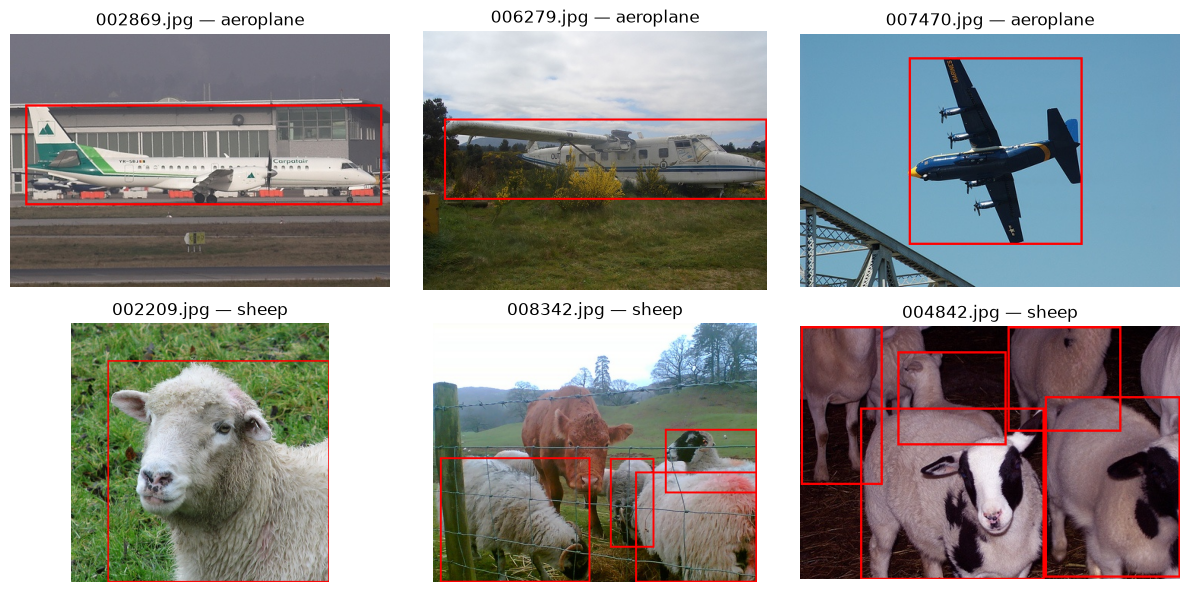

In [4]:
from PIL import Image as PILImage, ImageDraw
samples = manifest.query("split == 'train'").groupby('class').head(3)
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,row in zip(axes.ravel(),samples.to_dict('records')):
    image=PILImage.open(WORK/'dataset/images/train'/row['image']).convert('RGB')
    drawer=ImageDraw.Draw(image);w,h=image.size
    for line in (WORK/'dataset/labels/train'/Path(row['image']).with_suffix('.txt')).read_text().splitlines():
        c,cx,cy,bw,bh=map(float,line.split())
        drawer.rectangle([(cx-bw/2)*w,(cy-bh/2)*h,(cx+bw/2)*w,(cy+bh/2)*h],outline='red',width=3)
    ax.imshow(image);ax.set_title(f"{row['image']} — {row['class']}");ax.axis('off')
plt.tight_layout();plt.show()

## 4. Treinamentos independentes: 30 e 60 épocas
Usamos **YOLOv5u nano (`yolov5nu.pt`)**, uma variante oficial da família YOLOv5 com cabeça anchor-free, pela API Ultralytics. É uma escolha explícita: não se trata da implementação legada com anchors de `ultralytics/yolov5`.

Os dois experimentos começam dos mesmos pesos pré-treinados em COCO, semente 57, imagens de 320 pixels, batch 8, AdamW, taxa inicial 0,001, `workers=0`, determinismo e sem AMP. `patience=0` assegura executar todas as épocas. O checkpoint `best.pt` é escolhido pela validação; **o teste não seleciona o modelo**.

`RETRAIN=True` executa novamente os dois treinamentos e a CNN. Não altere os arquivos do repositório após a entrega; para repetir o experimento use uma cópia local ou seu Drive.

Usando pesos, CSVs e métricas dos treinamentos efetivamente executados.
Ative RETRAIN para reproduzir os treinamentos completos.


,épocas,divisão,tempo_treino_s,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),fitness
0,30,val,33.8929,0.8854,0.9167,0.9627,0.7945,0.7945
1,30,test,33.8929,0.8468,0.6500,0.7841,0.5254,0.5254
2,60,val,60.1302,0.9687,0.8757,0.9600,0.7135,0.7135
3,60,test,60.1302,0.8029,0.7125,0.7819,0.5222,0.5222


Curvas do experimento de 30 épocas:


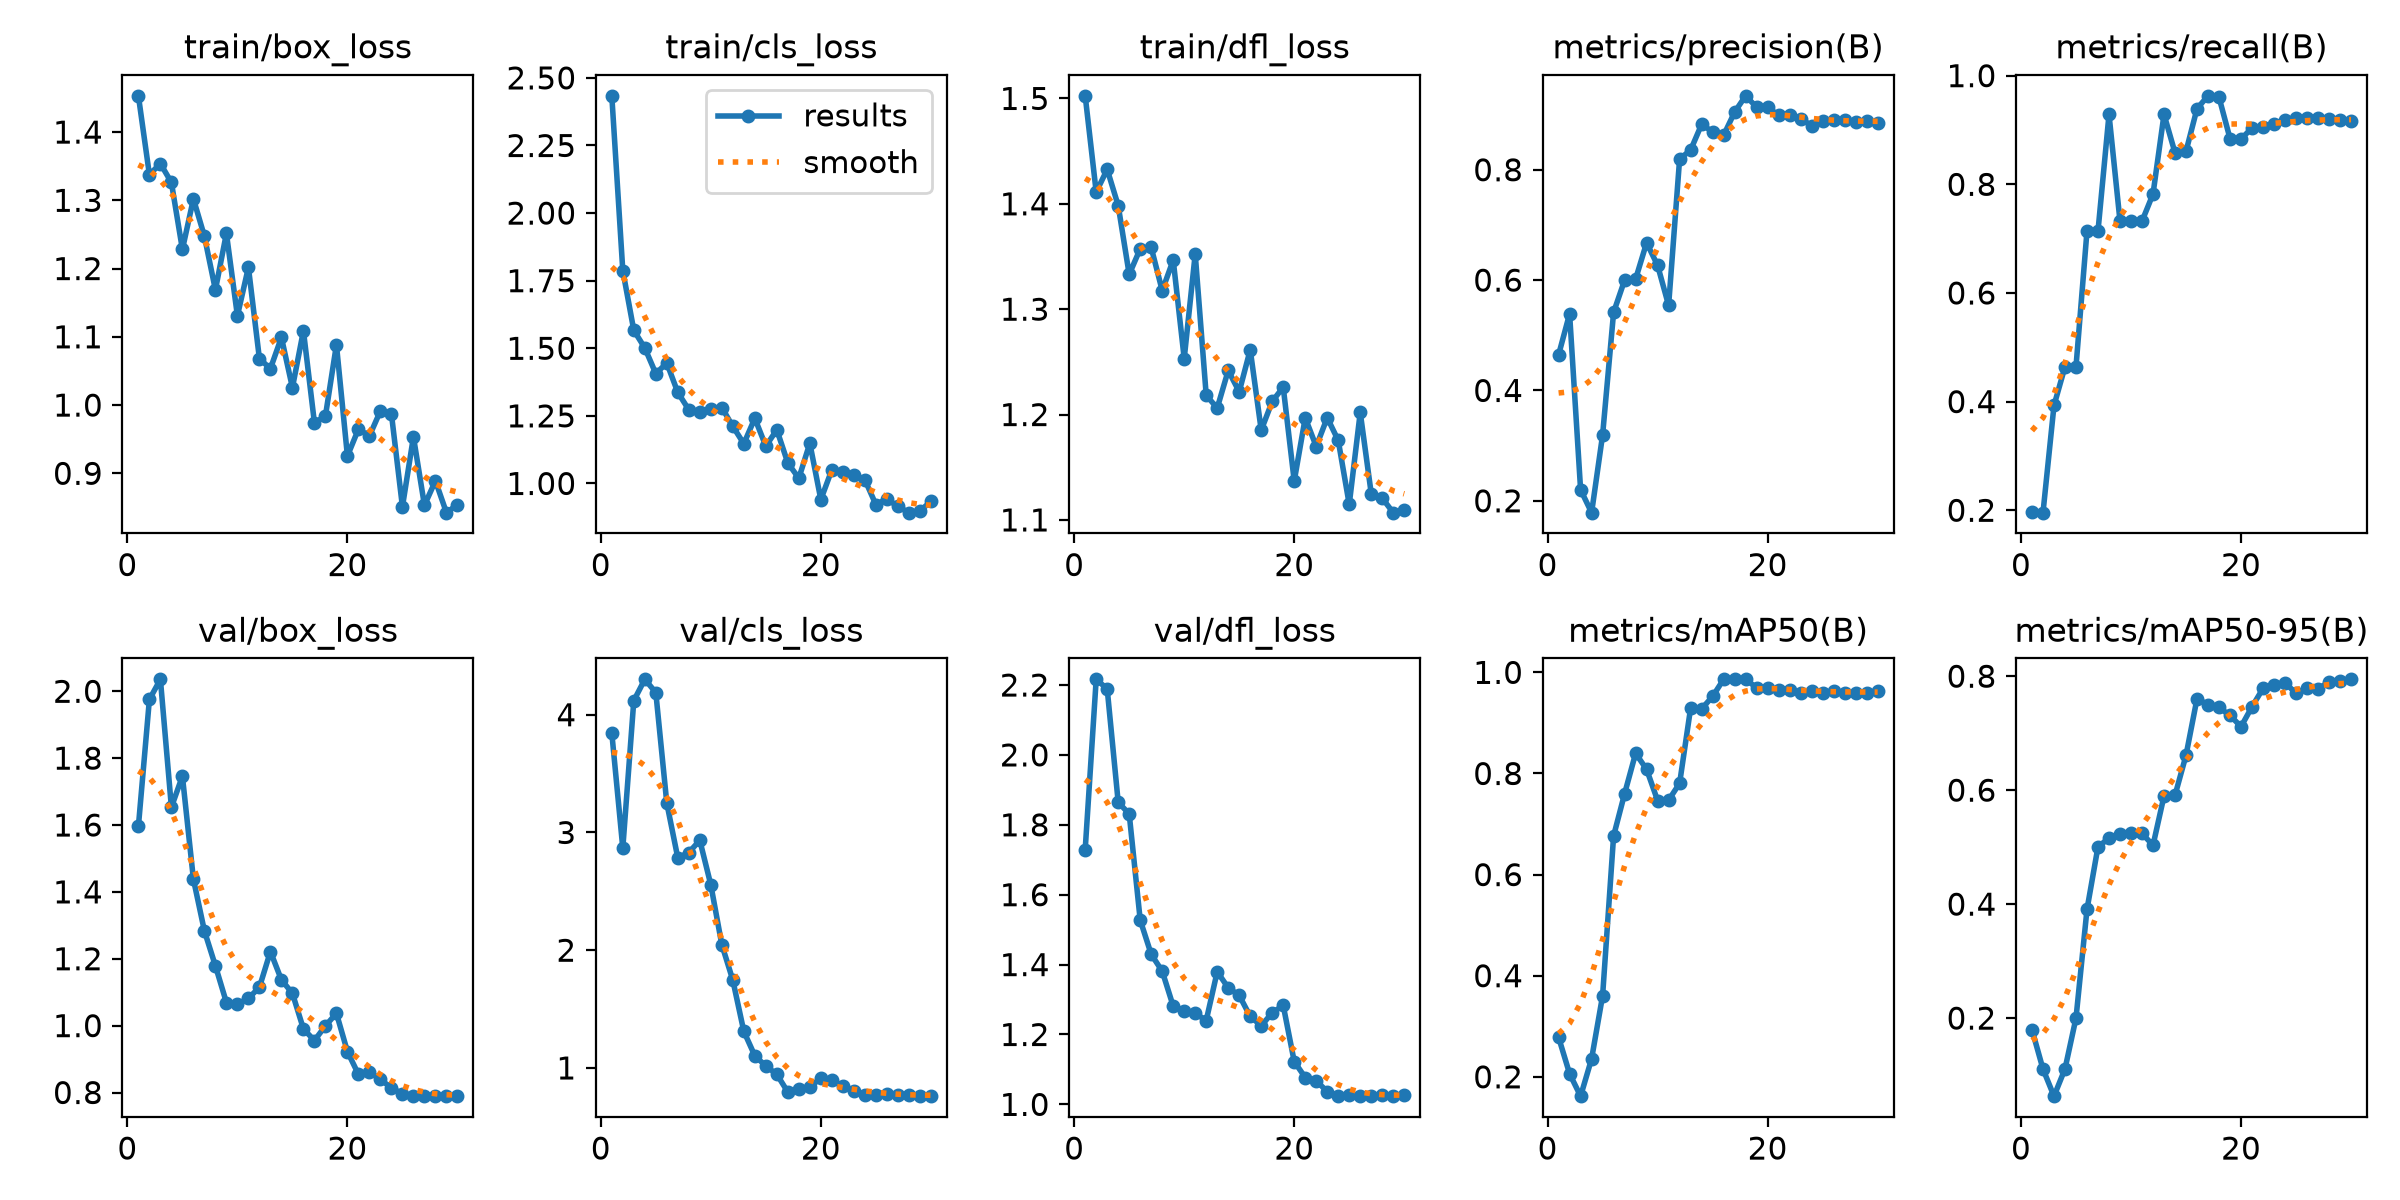

Curvas do experimento de 60 épocas:


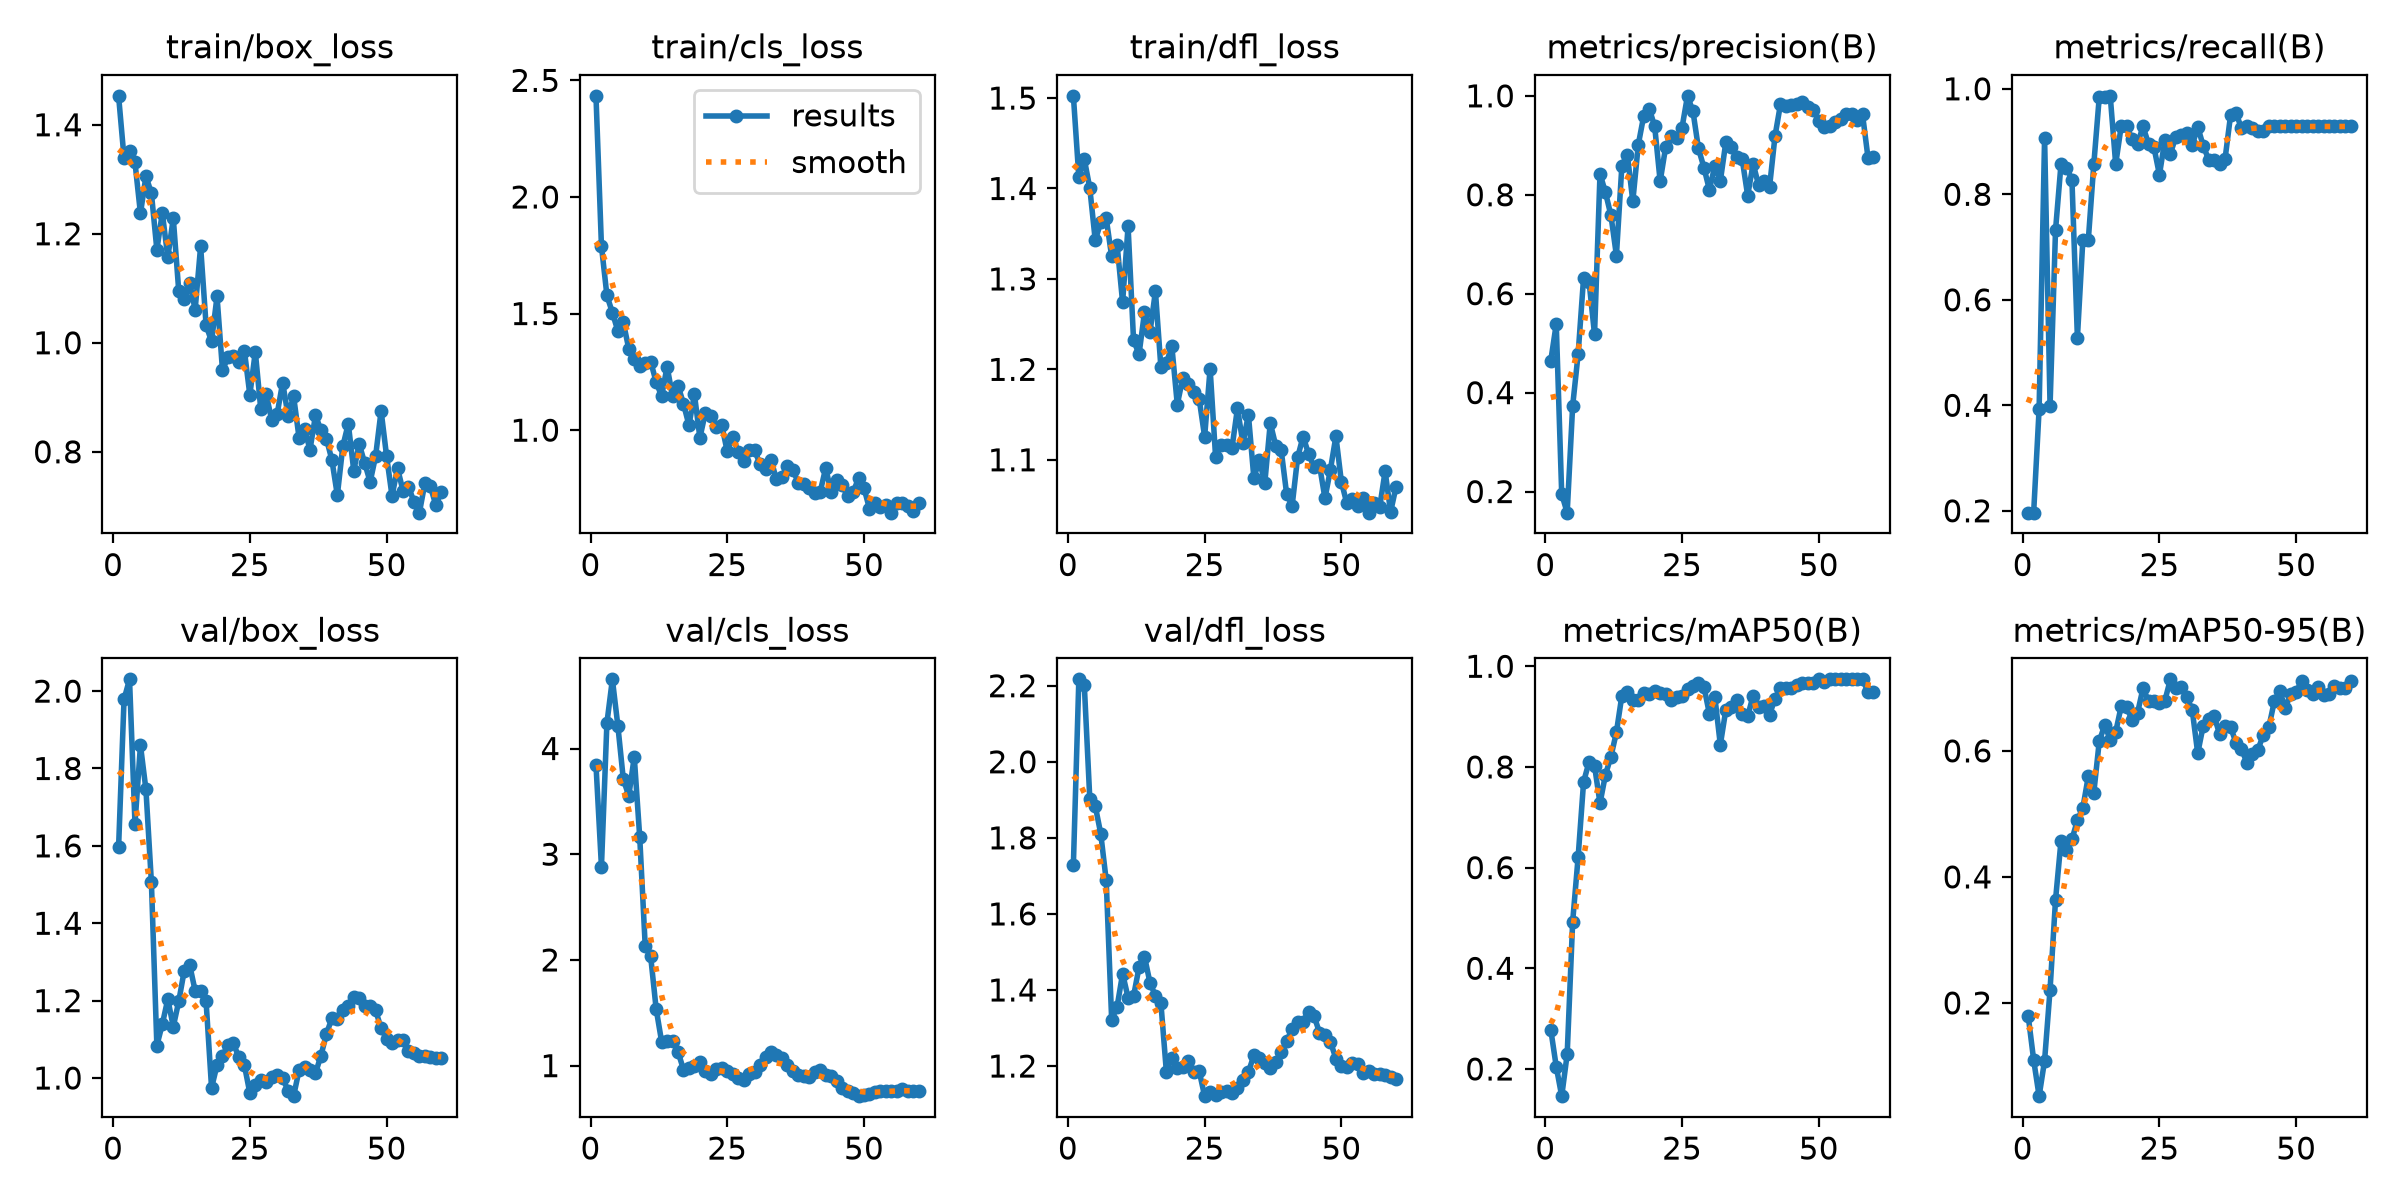

In [5]:
RETRAIN = False  # Altere para True apenas para repetir os treinamentos completos.
if RETRAIN:
    for epochs in [30,60]:
        exp.train_yolo(epochs)
    exp.train_cnn(30)
else:
    print('Usando pesos, CSVs e métricas dos treinamentos efetivamente executados.')
    print('Ative RETRAIN para reproduzir os treinamentos completos.')
records=[]
for epochs in [30,60]:
    summary=json.loads((WORK/f'results/yolo_{epochs}_summary.json').read_text())
    for split,metrics in summary['metrics'].items():
        records.append({'épocas':epochs,'divisão':split,'tempo_treino_s':summary['train_seconds'],**metrics})
display(pd.DataFrame(records).round(4))
for epochs in [30,60]:
    print(f'Curvas do experimento de {epochs} épocas:')
    display(NotebookImage(filename=str(WORK/f'results/yolo_{epochs}/results.png')))

## 5. Validação e teste reservados
**mAP@0,50** avalia classe e localização a IoU 0,50. **mAP@0,50:0,95** exige caixas progressivamente mais precisas. Não é adequado chamar mAP de “acurácia de classificação”. As métricas da biblioteca usam a curva de confiança; nossa tabela adicional usa um limiar operacional fixo de **confiança 0,25 e IoU 0,50**, com correspondência 1:1 entre caixa predita e real.

Abaixo, novas inferências são realmente executadas sobre o teste. `test_montage.png` conserva as evidências visuais da execução de entrega. Resultados podem variar levemente por versão e hardware.

,modelo,TP,FP,FN,precisão,recall,acurácia_imagem
0,yolo_30_test_eval,10,5,3,0.666667,0.769231,1.0
1,yolo_60_test_eval,9,2,4,0.818182,0.692308,1.0


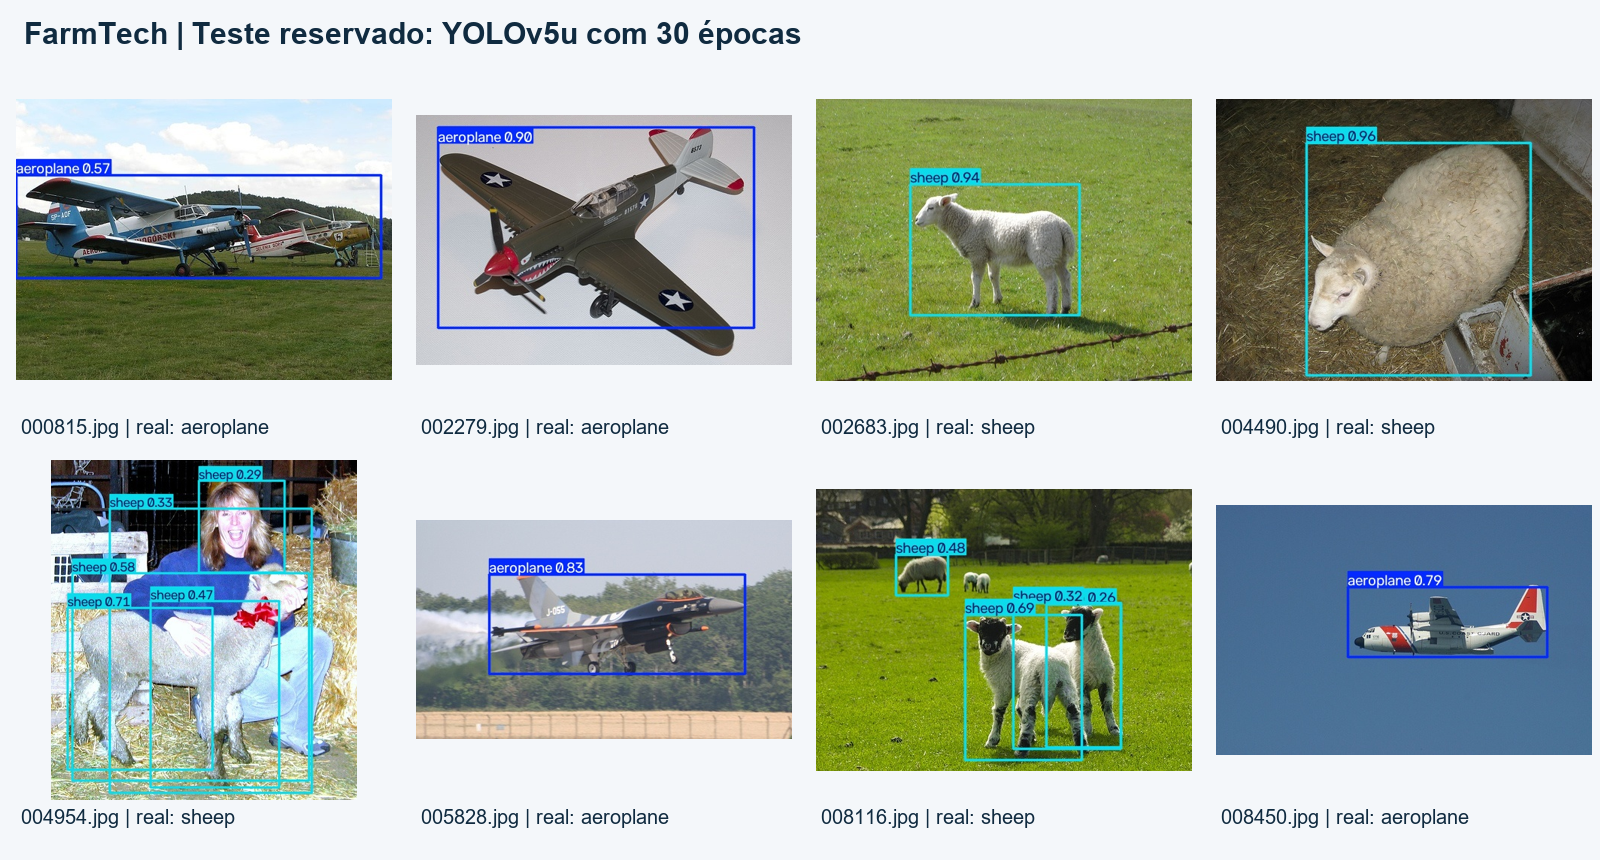

,image,true,predicted,correct,detections
0,000815.jpg,0,0,True,1
1,002279.jpg,0,0,True,1
2,002683.jpg,1,1,True,1
3,004490.jpg,1,1,True,1
4,004954.jpg,1,1,True,5
5,005828.jpg,0,0,True,1
6,008116.jpg,1,1,True,4
7,008450.jpg,0,0,True,1


In [6]:
model30=YOLO(str(WORK/'results/yolo_30/weights/best.pt'))
model60=YOLO(str(WORK/'results/yolo_60/weights/best.pt'))
test30=exp.evaluate_detector(model30,'yolo_30_test_eval')
test60=exp.evaluate_detector(model60,'yolo_60_test_eval')
display(pd.DataFrame([{'modelo':d['model'],'TP':d['tp'],'FP':d['fp'],'FN':d['fn'],
                      'precisão':d['precision_at_conf025_iou05'],'recall':d['recall_at_conf025_iou05'],
                      'acurácia_imagem':d['image_accuracy']} for d in [test30,test60]]))
display(NotebookImage(filename=str(WORK/'results/test_montage.png')))
display(pd.DataFrame(test30['images']))

## 6. Entrega 2: YOLO padrão e CNN treinada do zero
**YOLO padrão:** mesmos pesos COCO, sem customização. As classes COCO `airplane=4` e `sheep=18` são mapeadas para as duas classes do projeto. Essa abordagem já conhece os objetos, podendo funcionar sem treino específico, mas também fornece um referencial de transferência.

**CNN do zero:** três blocos convolucionais (16, 32, 64 canais), pooling, camada densa e dropout; **89.314 parâmetros**, inicializados aleatoriamente. Imagens de 96×96, Adam e entropia cruzada por 30 épocas. A validação escolhe maior acurácia, usando menor perda como desempate. A CNN apenas classifica a imagem e não localiza objetos.

Para comparar as quatro abordagens numa tarefa comum, convertemos cada detector em classificador de imagem usando a classe da detecção de maior confiança. Ausência de detecção é erro/abstenção. Essa métrica adicional não substitui as métricas de detecção.

,imagem,real,previsto
0,000815.jpg,0,0
1,002279.jpg,0,0
2,002683.jpg,1,1
3,004490.jpg,1,1
4,004954.jpg,1,1
5,005828.jpg,0,0
6,008116.jpg,1,1
7,008450.jpg,0,0


Acurácia CNN recalculada: 1.0
Tempo de treino registrado (s): 5.978885000000446


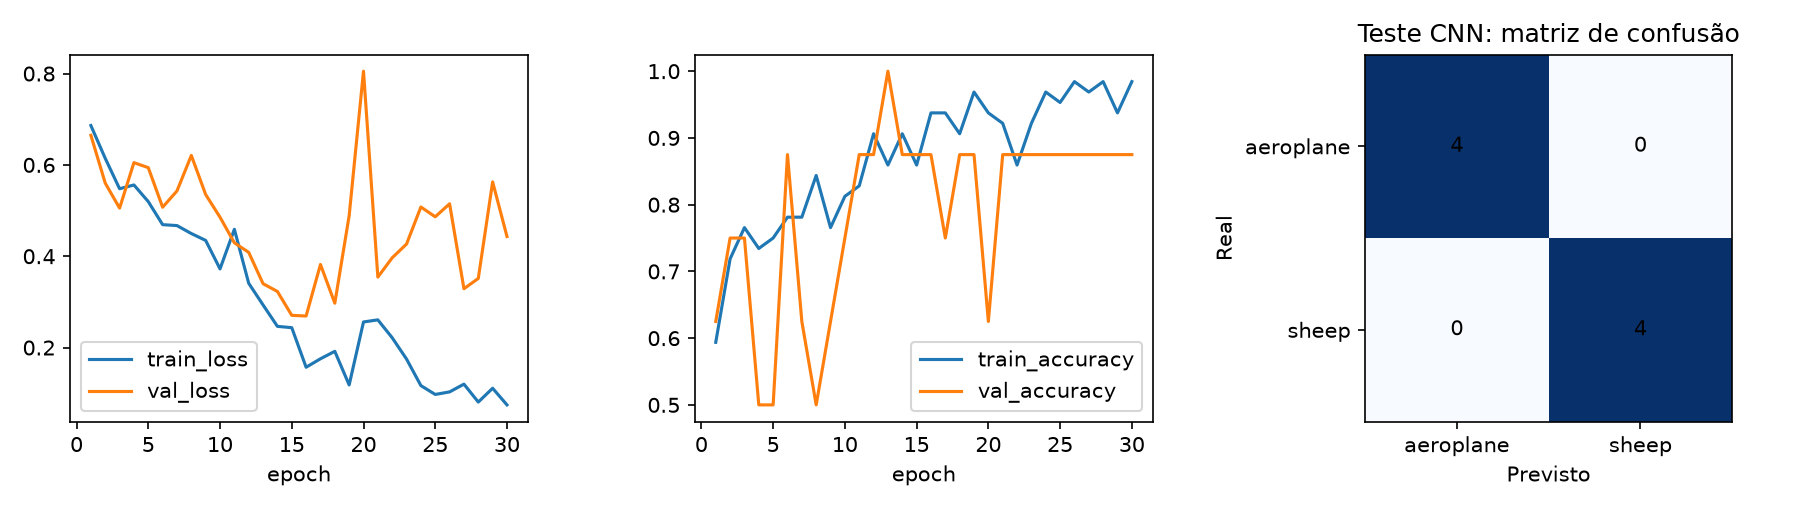

In [7]:
baseline=YOLO(str(WORK/'yolov5nu.pt')) if (WORK/'yolov5nu.pt').exists() else YOLO('yolov5nu.pt')
base_eval=exp.evaluate_detector(baseline,'baseline_coco',baseline=True)
cnn_info=json.loads((WORK/'results/cnn_summary.json').read_text())
cnn=exp.TinyCNN().to(exp.DEVICE)
cnn.load_state_dict(torch.load(WORK/'results/cnn/best.pt',map_location=exp.DEVICE,weights_only=True));cnn.eval()
test_ds=exp.ImageDataset('test')
with torch.no_grad():
    x=torch.stack([test_ds[i][0] for i in range(len(test_ds))]).to(exp.DEVICE)
    predictions=cnn(x).argmax(1).cpu().tolist()
cnn_check=pd.DataFrame([{'imagem':r['image'],'real':r['class_id'],'previsto':p} for r,p in zip(test_ds.rows,predictions)])
display(cnn_check)
print('Acurácia CNN recalculada:', (cnn_check.real==cnn_check.previsto).mean())
print('Tempo de treino registrado (s):',cnn_info['train_seconds'])
display(NotebookImage(filename=str(WORK/'results/cnn/curves.png')))

## 7. Comparação crítica: precisão, tempo e integração
Os tempos publicados abaixo vêm da execução original na **RTX 2060 SUPER**. A medição de inferência usa 3 aquecimentos e mediana de 5 repetições sobre as 8 imagens; YOLO inclui pré/pós-processamento em memória, CNN mede apenas o forward do tensor já preparado. Por isso o tempo muito menor da CNN não implica equivalência de serviço. Também diferem as resoluções (320 e 96).

| Abordagem | Uso e integração | Vantagem | Limitação |
|---|---|---|---|
| YOLO customizado | Dataset anotado + treinamento; API `train/val/predict` | Localiza objetos e adapta classes | Custo de rotulação, treino e falsos positivos/negativos |
| YOLO COCO padrão | Carregar pesos e filtrar classes | Integração mais simples; zero treino local | Limitado às classes existentes e domínio de pré-treino |
| CNN do zero | Dataset por classe + rede própria | Menos parâmetros e inferência rápida | Não localiza; propensa a viés de fundo e overfitting |

Não calculamos mAP para CNN, pois ela não produz caixas. Valores vazios são “não aplicáveis”, não zero.

,modelo,epocas,acuracia_imagem_teste,erro_imagem_teste,precisao_deteccao,recall_deteccao,mAP50_teste,mAP50_95_teste,treinamento_s,inferencia_ms_imagem
0,YOLOv5u 30 épocas,30,1.000,0.000,0.6667,0.7692,0.7841,0.5254,33.8929,3.4803
1,YOLOv5u 60 épocas,60,1.000,0.000,0.8182,0.6923,0.7819,0.5222,60.1302,3.4334
2,YOLOv5u COCO padrão,0,0.875,0.125,0.7500,0.6923,NaN,NaN,0.0000,3.1552
3,CNN do zero,30,1.000,0.000,NaN,NaN,NaN,NaN,5.9789,0.0691


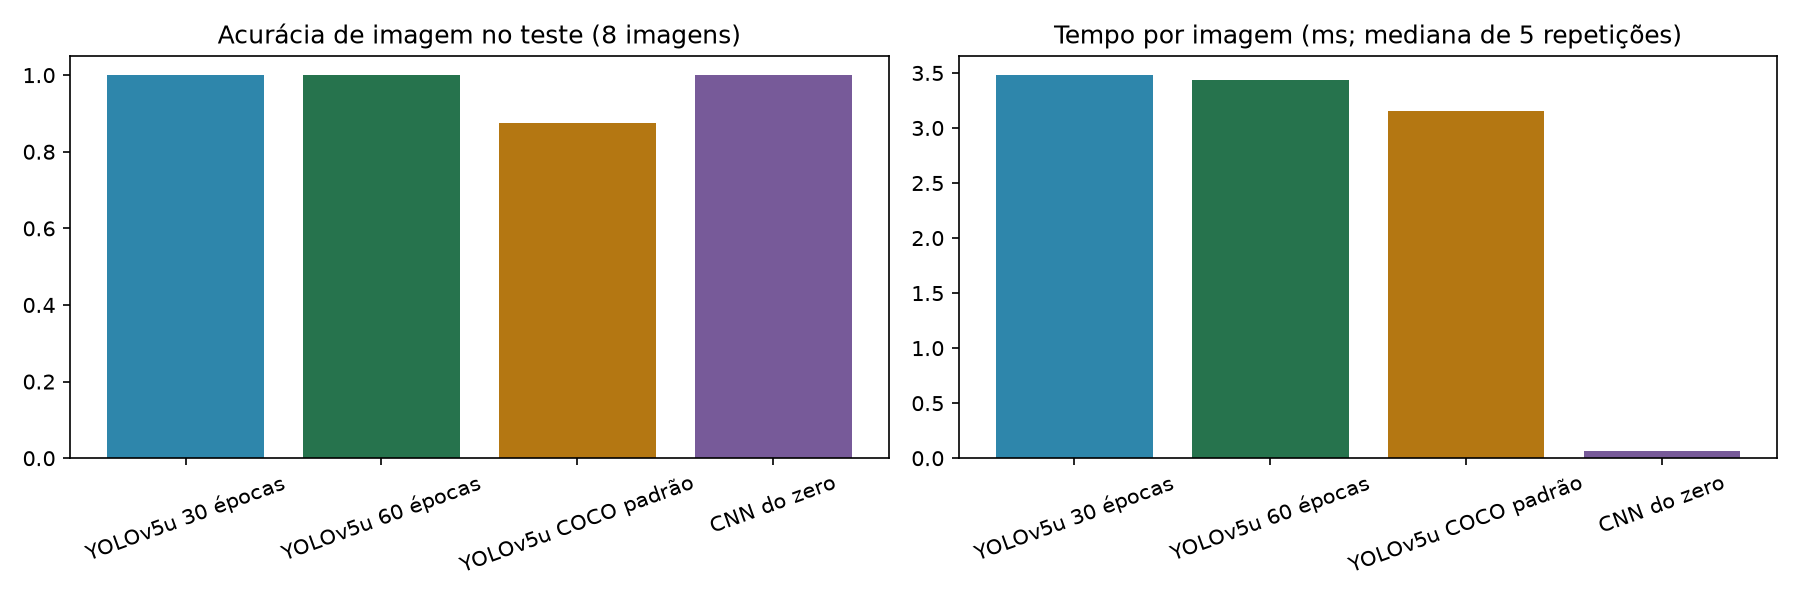

Perdas ao final de 30 épocas (não confundir com taxa de erro):


,epoch,train/box_loss,train/cls_loss,train/dfl_loss,val/box_loss,val/cls_loss,val/dfl_loss
29,30,0.8541,0.9338,1.1091,0.7896,0.763,1.0274


Perdas ao final de 60 épocas (não confundir com taxa de erro):


,epoch,train/box_loss,train/cls_loss,train/dfl_loss,val/box_loss,val/cls_loss,val/dfl_loss
59,60,0.7261,0.6866,1.0702,1.0507,0.7562,1.1657


In [8]:
published=pd.read_csv(WORK/'results/comparison.csv')
display(published.round(4))
display(NotebookImage(filename=str(WORK/'results/comparison.png')))
for epochs in [30,60]:
    curves=pd.read_csv(WORK/f'results/yolo_{epochs}/results.csv')
    cols=[c for c in curves.columns if 'loss' in c]
    print(f'Perdas ao final de {epochs} épocas (não confundir com taxa de erro):')
    display(curves[['epoch',*cols]].tail(1).round(4))

## 8. Conclusões e limites
1. **30 épocas são suficientes para esta demonstração.** O mAP@0,50:0,95 da validação foi **0,7945** em 30 épocas e **0,7135** em 60. Isso favorece escolher o modelo de 30 épocas pela validação. No teste, o mAP@0,50 foi **0,7841** e **0,7819**, respectivamente; o mAP@0,50:0,95 foi **0,5254** e **0,5222**. Aumento de épocas não garante melhora de generalização.
2. **Acurácia de imagem não é detecção perfeita.** As duas versões customizadas e a CNN classificaram 8/8 imagens; YOLO padrão acertou 7/8. No limiar operacional, YOLO de 30 épocas teve **10 TP, 5 FP e 3 FN**; o de 60 teve **9 TP, 2 FP e 4 FN**. O segundo produziu menos falsos positivos, mas perdeu mais objetos. Essa é uma troca relevante para um cliente.
3. **O custo adicional foi medido.** Treinos YOLO levaram aproximadamente **33,9 s** e **60,1 s** nesta base reduzida/GPU; CNN levou **6,0 s**. Esses tempos não podem ser extrapolados para bases grandes ou ambientes sem GPU.
4. **Incerteza elevada:** há apenas 8 imagens de teste (4 por classe), e cada erro de imagem altera a acurácia em 12,5 pontos percentuais. Uma base pequena e visualmente fácil não sustenta alegações de desempenho comercial.
5. **Vieses e limites:** seleção exclui objetos pequenos/difíceis e favorece uma classe por imagem; fundos (céu/pasto) podem ajudar a CNN sem compreensão do objeto. COCO e VOC vêm de imagens da internet; não verificamos sobreposição no pré-treino externo. Não há duplicatas dentro das divisões locais, mas isso não comprova independência em relação ao pré-treinamento.
6. **Próximos passos:** coletar dados do cliente com consentimento, incluir ambos os objetos na mesma cena e imagens negativas, testar iluminação/distância/oclusões, usar teste externo maior, revisar rótulos e ajustar limiar com a validação. A aplicação deve proteger imagens e acesso, avaliar deriva de dados e manter supervisão humana.

O projeto demonstra funcionamento, não promete um sistema infalível. Os módulos opcionais “Ir Além” não integram esta entrega obrigatória.

## Fontes
- [PASCAL VOC2007 — dados e documentação](https://www.robots.ox.ac.uk/~vgg/projects/pascal/VOC/voc2007/)
- [Ultralytics YOLOv5u — arquitetura e API](https://docs.ultralytics.com/models/yolov5/)
- [Make Sense — ferramenta de anotação](https://www.makesense.ai/)
- [PyTorch — documentação](https://docs.pytorch.org/docs/stable/index.html)
- [Ultralytics — métricas de detecção](https://docs.ultralytics.com/guides/yolo-performance-metrics/)

Os registros de execução, CSVs, pesos e imagens anotadas acompanham o notebook em `results.zip`.